# Лабораторная работа №3. Анализ данных по методологии CRISP-DM
## Прогнозирование качества вина (Wine Quality)

**Дисциплина:** «Проект — применение машинного обучения в креативных индустриях»  
**Преподаватель:** Трубчик Ирина Степановна  
**Выполнил:** Елманов И. В., группа МИК21  
**Дата:** 26 октября 2026 г.

**Задание:** решить задачу с винами, используя CRISP-DM-подход; представить
Jupyter Notebook на GitHub или Colab по ссылке с доступом на просмотр.

[Задание ДО.СКИФ](https://do.skif.donstu.ru/mod/assign/view.php?id=107173) ·
[Датасет из задания](https://www.kaggle.com/datasets/rajyellow46/wine-quality)

### Содержание
1. Понимание бизнес-задачи (Business Understanding).
2. Понимание данных (Data Understanding).
3. Подготовка данных (Data Preparation).
4. Моделирование (Modeling).
5. Оценка результатов (Evaluation).
6. Применение и сопровождение (Deployment).

**Воспроизведение:** в Colab выбрать «Среда выполнения → Выполнить всё».
Данные автоматически скачиваются из Kaggle (версия 1, без ключа API), если CSV
не лежит рядом. Для локального запуска зависимости указаны в `requirements.txt`.
На обучении фиксируется `random_state=42`; все результаты ниже вычисляются кодом.

In [1]:
# При необходимости в новой среде раскомментируйте и выполните:
# %pip install pandas numpy scikit-learn matplotlib seaborn joblib
%matplotlib inline
from pathlib import Path
from io import BytesIO
from urllib.request import Request, urlopen
from zipfile import ZipFile
import hashlib
import importlib.metadata
import json
import platform

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
N_JOBS = 2
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', font='DejaVu Sans', context='notebook')
plt.rcParams.update({'figure.figsize': (10, 5), 'figure.dpi': 110})
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
versions = {p: importlib.metadata.version(p) for p in
            ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'seaborn', 'joblib']}
print('Python:', platform.python_version())
display(pd.Series(versions, name='Версия'))

Python: 3.13.5


pandas           3.1.0
numpy            2.5.4
scikit-learn     1.9.1
matplotlib      3.11.2
seaborn         0.13.2
joblib           1.6.0
Name: Версия, dtype: str

## 1. Business Understanding — понимание бизнес-задачи

**Учебный сценарий:** винодельня хочет предварительно оценивать качество вина
по результатам физико-химического анализа, чтобы планировать экспертную дегустацию.
Это постановка для данной работы, а не описание реально внедрённой системы.

**Цель анализа:** построить модель, прогнозирующую `quality` — экспертную оценку
от 0 до 10 — по 11 физико-химическим показателям и типу вина `type`.
В описании Kaggle разрешены классификация и регрессия. Выбираем **регрессию**:
оценки упорядочены, и ошибка на три балла существенно хуже ошибки на один балл.
Дробный прогноз интерпретируется как оценка ожидаемого качества, не как новая
шкала экспертных баллов.

**План оценки, заданный до обучения:**
- Основная метрика **MAE**: среднее абсолютное отклонение от экспертной оценки,
  в баллах. Чем меньше, тем лучше.
- **RMSE** дополнительно сильнее штрафует крупные ошибки; **R²** показывает
  качество относительно прогноза среднего тестовой выборки.
- Доля прогнозов с абсолютной ошибкой ≤ 1 балла — дополнительная понятная метрика.
- Базовая модель всегда предсказывает медиану обучающих оценок. Медиана
  соответствует минимизации MAE.
- Учебный критерий успеха: на отложенном тесте MAE выбранной модели как минимум
  на **10% ниже** MAE базовой модели. Это собственный критерий эксперимента,
  не требование преподавателя и не подтверждённый бизнес-порог.

**Ограничения:** нет цен, сортов винограда, времени производства, идентификаторов
партий и индивидуальных оценок дегустаторов. Нельзя оценить экономический эффект,
проверить временную устойчивость или заменить моделью профессиональную дегустацию.

## 2. Data Understanding — понимание данных

### 2.1. Источник и загрузка

Используем именно **объединённый датасет `winequalityN.csv`** по ссылке задания,
а не только красные вина из другой версии Wine Quality.
По описанию автора Kaggle, объединены красные и белые португальские вина
Vinho Verde, а часть значений случайно удалена. Исходные данные — UCI;
ссылка на публикацию приведена в конце ноутбука. Способ удаления пропусков
самостоятельно не проверялся.

Скачивание закреплено за версией 1. SHA-256 позволяет обнаружить изменение файла.

In [2]:
DATA_URL = ('https://www.kaggle.com/api/v1/datasets/download/'
            'rajyellow46/wine-quality?datasetVersionNumber=1')
EXPECTED_SHA256 = 'cb01f91c70de066f85d4cffac3bb163e4719523861cd79ba8825b722cf98b48c'
DATA_PATH = Path('winequalityN.csv')
if not DATA_PATH.exists():
    archive_path = Path('wine-quality.zip')
    if archive_path.exists():
        archive_bytes = archive_path.read_bytes()
    else:
        request = Request(DATA_URL, headers={'User-Agent': 'WineQualityLab/1.0'})
        with urlopen(request, timeout=90) as response:
            archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        DATA_PATH.write_bytes(archive.read('winequalityN.csv'))

data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert data_sha256 == EXPECTED_SHA256, 'Файл отличается от зафиксированной версии'
raw = pd.read_csv(DATA_PATH)
assert raw.shape == (6497, 13)
assert raw['quality'].notna().all()
assert raw['quality'].between(0, 10).all()
assert set(raw['type'].unique()) == {'red', 'white'}
print('Размер исходной таблицы:', raw.shape)
print('SHA-256:', data_sha256)
display(raw.head())

Размер исходной таблицы: (6497, 13)
SHA-256: cb01f91c70de066f85d4cffac3bb163e4719523861cd79ba8825b722cf98b48c


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


### 2.2. Словарь признаков

| Поле | Смысл | Роль |
|---|---|---|
| `type` | Красное (`red`) / белое (`white`) вино | Категориальный признак |
| `fixed acidity` | Нелетучая кислотность | Числовой признак |
| `volatile acidity` | Летучая кислотность | Числовой признак |
| `citric acid` | Содержание лимонной кислоты | Числовой признак |
| `residual sugar` | Остаточный сахар | Числовой признак |
| `chlorides` | Содержание хлоридов | Числовой признак |
| `free sulfur dioxide` | Свободный диоксид серы | Числовой признак |
| `total sulfur dioxide` | Общий диоксид серы | Числовой признак |
| `density` | Плотность | Числовой признак |
| `pH` | Кислотность по шкале pH | Числовой признак |
| `sulphates` | Содержание сульфатов | Числовой признак |
| `alcohol` | Содержание спирта | Числовой признак |
| `quality` | Экспертная оценка, шкала 0–10 | **Целевая переменная** |

### 2.3. Аудит качества

Сначала проверяем схему, пропуски, дубликаты и допустимость цели на всей таблице.
Развёрнутый EDA и все решения по обучению далее основаны только на train.

In [3]:
audit = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'пропусков': raw.isna().sum(),
    'пропусков, %': raw.isna().mean().mul(100),
    'уникальных': raw.nunique(),
})
display(audit)
n_duplicates = int(raw.duplicated().sum())
print('Полных дубликатов:', n_duplicates)
print('Всего пропущенных ячеек:', int(raw.isna().sum().sum()))

,тип,пропусков,"пропусков, %",уникальных
type,str,0,0.0000,2
fixed acidity,float64,10,0.1539,106
volatile acidity,float64,8,0.1231,187
citric acid,float64,3,0.0462,89
residual sugar,float64,2,0.0308,316
chlorides,float64,2,0.0308,214
free sulfur dioxide,float64,0,0.0000,135
total sulfur dioxide,float64,0,0.0000,276
density,float64,0,0.0000,998
pH,float64,9,0.1385,108


Полных дубликатов: 1168
Всего пропущенных ячеек: 38


## 3. Data Preparation — подготовка данных

### 3.1. Протокол эксперимента и защита от утечки

1. Удаляем только **полные совпадения строк** (включая цель), оставляя первое.
   Без идентификаторов партий нельзя доказать, что это технические повторы:
   это явное допущение, меняющее веса наблюдений в пользу уникальных записей.
2. Формируем группы по одинаковым **исходным входным признакам**, без `quality`.
   Даже если у одинаковых признаков разные оценки, они остаются в одной группе.
3. Отделяем около 20% групп в тест, фиксируя seed. Тест не используется
   при выборе модели, гиперпараметров, медиан и масштабирования.
4. На оставшемся train сравниваем модели через **5-fold GroupKFold**.
   Группы не пересекаются между обучением и валидацией каждого фолда.
5. Импутация медианой, стандартизация и кодирование типа входят в `Pipeline`
   и обучаются заново внутри каждого фолда.

Группировка предотвращает пересечение **точно одинаковых доступных признаков**.
Разные маски пропусков или почти одинаковые измерения одной партии этим способом
не выявляются; отсутствие идентификаторов — ограничение оценки.

In [4]:
data = raw.drop_duplicates().reset_index(drop=True)
X = data.drop(columns='quality')
y = data['quality'].astype(int)
groups = pd.util.hash_pandas_object(X, index=False).astype(str)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(groups_train).isdisjoint(set(groups_test))
assert set(train_idx).isdisjoint(set(test_idx))
numeric_features = X_train.select_dtypes(include='number').columns.tolist()
categorical_features = ['type']
print('После удаления дубликатов:', data.shape)
print(f'Train: {len(X_train)} строк, test: {len(X_test)} строк')
print(f'Фактическая доля test: {len(X_test) / len(data):.2%}')
print('Пересечение групп train и test: 0')
pd.DataFrame({'row_after_dedup': np.arange(len(data)), 'group': groups,
              'split': np.where(data.index.isin(train_idx), 'train', 'test')}
             ).to_csv(ARTIFACTS / 'split.csv', index=False)

После удаления дубликатов: (5329, 13)
Train: 4263 строк, test: 1066 строк
Фактическая доля test: 20.00%
Пересечение групп train и test: 0


### 3.2. Исследовательский анализ обучающей выборки

Исследуем распределение цели, баланс типов, числовые признаки и связи с оценкой.
Оценки редких уровней могут быть нестабильны, поэтому одной общей метрики
недостаточно. Корреляции описывают ассоциации, а не причинные зависимости.

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4253.0,7.2195,1.3417,3.8000,6.4000,6.9000,7.7000,15.900
volatile acidity,4258.0,0.3424,0.1681,0.0800,0.2300,0.2950,0.4100,1.580
citric acid,4262.0,0.3193,0.1470,0.0000,0.2500,0.3100,0.4000,1.230
residual sugar,4261.0,5.0729,4.5446,0.6000,1.8000,2.7000,7.5000,65.800
chlorides,4261.0,0.0566,0.0370,0.0090,0.0380,0.0470,0.0660,0.610
free sulfur dioxide,4263.0,30.0816,17.9053,1.0000,16.0000,28.0000,41.0000,289.000
total sulfur dioxide,4263.0,114.3839,56.8597,6.0000,75.0000,117.0000,154.0000,440.000
density,4263.0,0.9946,0.0030,0.9871,0.9922,0.9947,0.9968,1.039
pH,4254.0,3.2239,0.1602,2.7400,3.1100,3.2150,3.3300,4.010
sulphates,4259.0,0.5314,0.1476,0.2200,0.4300,0.5100,0.6000,2.000


type,red,white
quality,,
3,10,19
4,44,115
5,454,936
6,424,1455
7,132,553
8,13,104
9,0,4


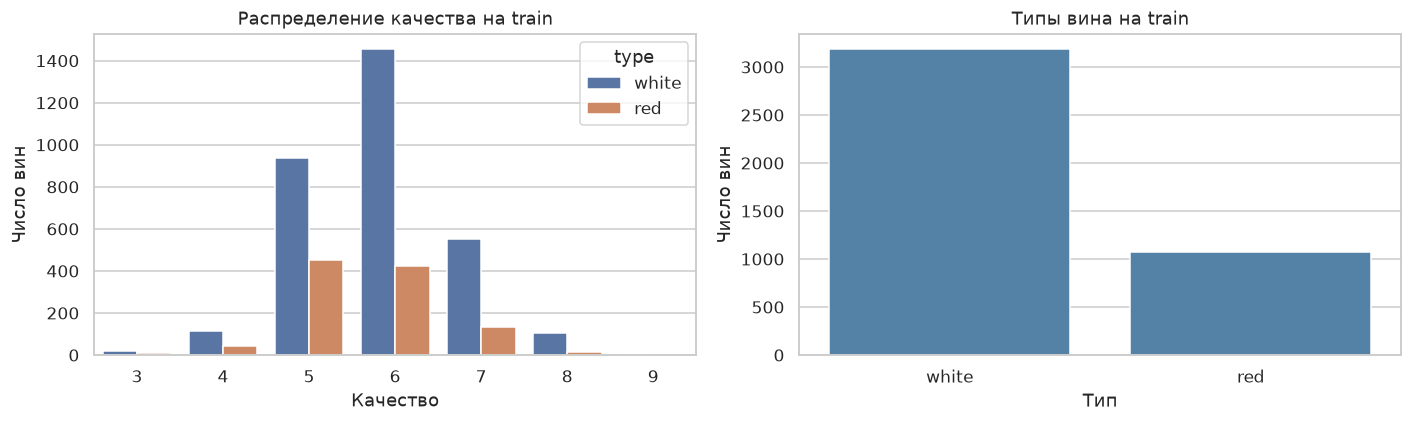

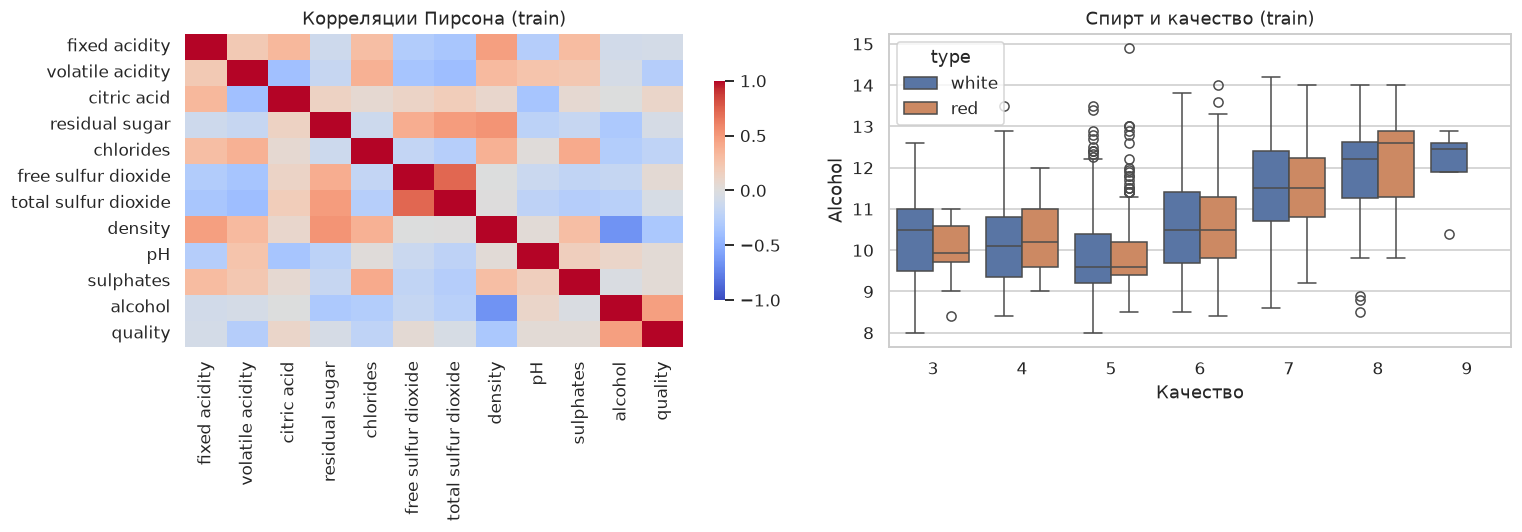

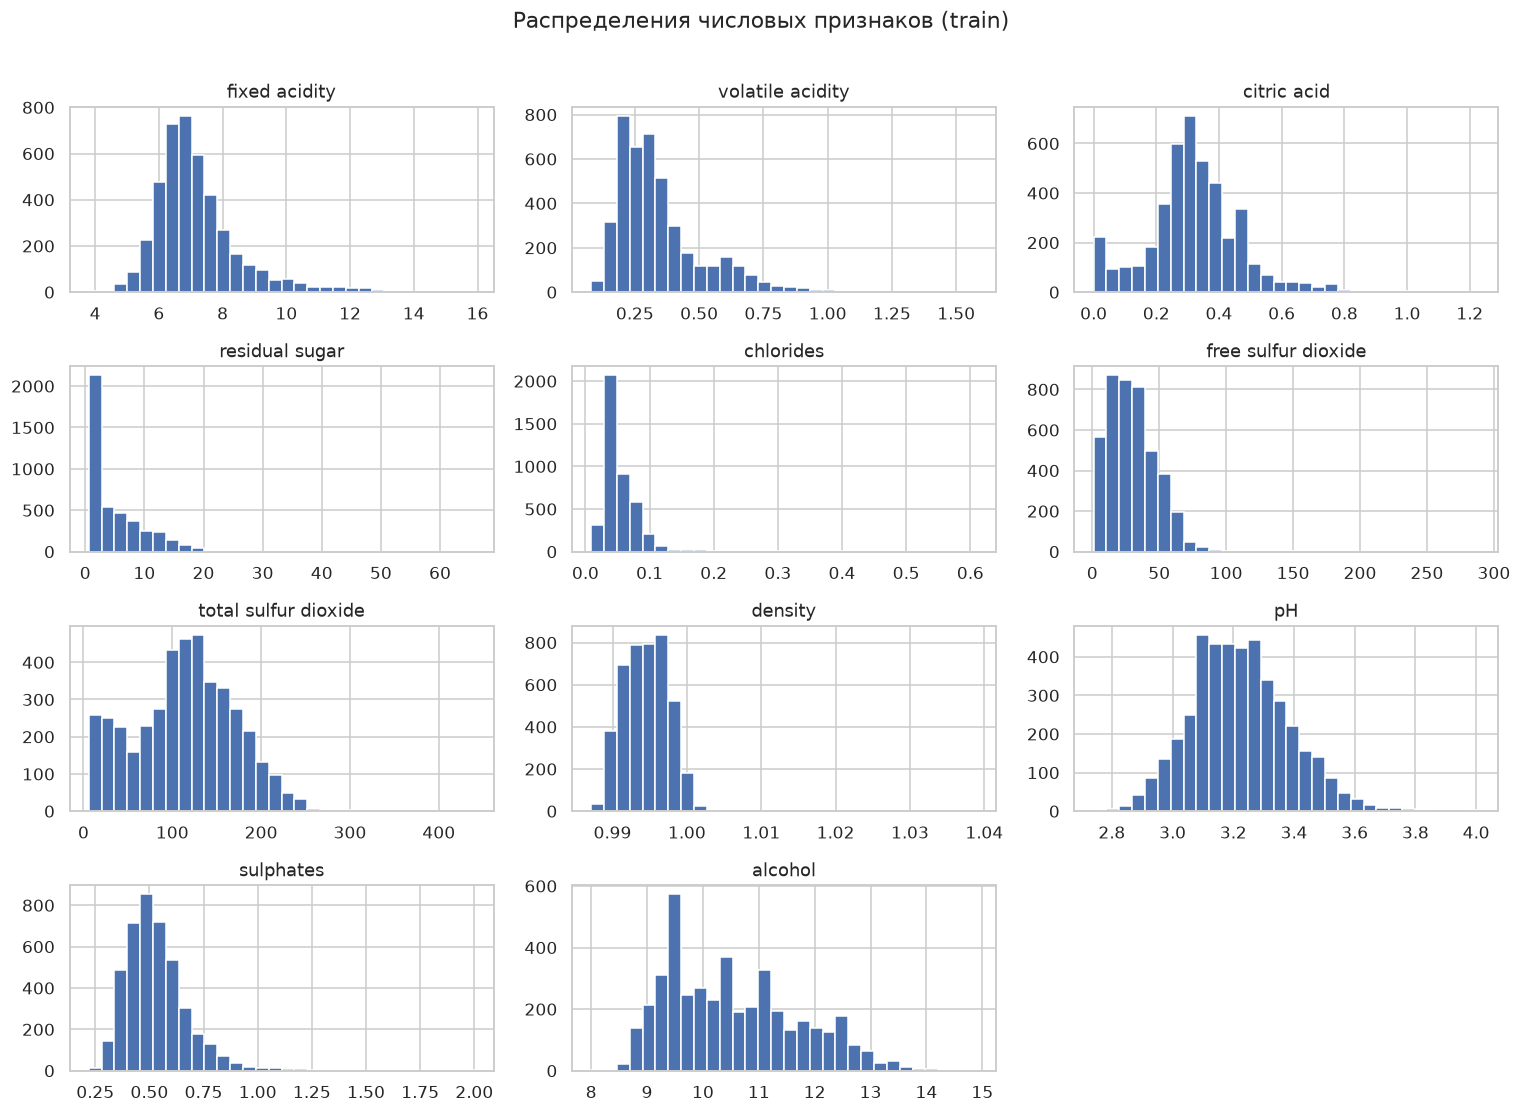

,Корреляция с quality на train
density,-0.3235
volatile acidity,-0.2732
chlorides,-0.2091
fixed acidity,-0.0748
residual sugar,-0.0589
total sulfur dioxide,-0.0498
pH,0.0395
sulphates,0.0460
free sulfur dioxide,0.0514
citric acid,0.1054


**Наблюдения EDA:** наиболее сильная положительная линейная связь среди числовых признаков — `alcohol` (0.469), отрицательная — `density` (-0.324). Связи могут зависеть от типа вина и других показателей. Гистограммы показывают различия масштабов и асимметрию распределений.

In [5]:
train = X_train.assign(quality=y_train)
display(train.describe().T)
display(pd.crosstab(train['quality'], train['type']))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=train, x='quality', hue='type', ax=axes[0])
axes[0].set(title='Распределение качества на train', xlabel='Качество', ylabel='Число вин')
sns.countplot(data=train, x='type', ax=axes[1], color='steelblue')
axes[1].set(title='Типы вина на train', xlabel='Тип', ylabel='Число вин')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(train[numeric_features + ['quality']].corr(), cmap='coolwarm', center=0,
            vmin=-1, vmax=1, ax=axes[0], cbar_kws={'shrink': 0.7})
axes[0].set_title('Корреляции Пирсона (train)')
sns.boxplot(data=train, x='quality', y='alcohol', hue='type', ax=axes[1])
axes[1].set(title='Спирт и качество (train)', xlabel='Качество', ylabel='Alcohol')
plt.tight_layout()
plt.show()

train[numeric_features].hist(bins=30, figsize=(14, 10))
plt.suptitle('Распределения числовых признаков (train)', y=1.01)
plt.tight_layout()
plt.show()

correlations = train[numeric_features].corrwith(y_train).sort_values()
display(correlations.to_frame('Корреляция с quality на train'))
positive = correlations.idxmax()
negative = correlations.idxmin()
display(Markdown(
    f'**Наблюдения EDA:** наиболее сильная положительная линейная связь среди '
    f'числовых признаков — `{positive}` ({correlations[positive]:.3f}), '
    f'отрицательная — `{negative}` ({correlations[negative]:.3f}). '
    'Связи могут зависеть от типа вина и других показателей. '
    'Гистограммы показывают различия масштабов и асимметрию распределений.'
))

### 3.3. Решения по обработке

- Пропуски в числовых полях заполняем **медианой train соответствующего фолда**,
  не удаляя немногочисленные неполные строки. Медиана менее чувствительна
  к экстремальным значениям, чем среднее.
- Числовые признаки стандартизируем. Это важно для Ridge; для деревьев
  линейное изменение масштаба не является необходимым, но единый препроцессор
  делает сравнение и применение согласованными.
- Тип вина кодируем One-Hot Encoding. Неизвестная категория при предсказании
  не вызывает технической ошибки, однако требует проверки входных данных.
- Экстремальные значения не удаляем автоматически: нет подтверждения, что
  это ошибки измерения. Отбор по всей таблице мог бы исказить тестовую оценку.
- `quality` не включается в признаки. Не балансируем и не округляем цель
  перед обучением: решается задача регрессии.

In [6]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('type', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
])

def make_pipeline(estimator):
    return Pipeline([('preprocess', clone(preprocessor)), ('model', estimator)])

cv = GroupKFold(n_splits=5)
for fit_idx, valid_idx in cv.split(X_train, y_train, groups_train):
    assert set(groups_train.iloc[fit_idx]).isdisjoint(set(groups_train.iloc[valid_idx]))
print('Проверено отсутствие пересечения групп на всех 5 фолдах.')

Проверено отсутствие пересечения групп на всех 5 фолдах.


## 4. Modeling — моделирование

Сравниваем четыре подхода на одинаковых фолдах:

| Модель | Назначение | Проверяемые параметры |
|---|---|---|
| Dummy (медиана) | Базовая точка отсчёта | Без подбора |
| Ridge | Регуляризованная линейная модель | `alpha`: 0.1, 1, 10 |
| Random Forest | Нелинейный ансамбль деревьев | `min_samples_leaf`: 1, 3, 5 |
| HistGradientBoosting | Последовательный ансамбль деревьев | `max_leaf_nodes`: 15, 31; `l2_regularization`: 1, 10 |

Подбор — небольшой `GridSearchCV`, целевая метрика `neg_mean_absolute_error`.
Лучшая модель выбирается **только по средней CV MAE**, затем уже переобучается
на всём train (`refit=True`). Стандартное отклонение по фолдам описывает разброс,
но не является доверительным интервалом. Итоговая оценка — на отложенном test.

In [7]:
experiments = {
    'Dummy (median)': (DummyRegressor(strategy='median'), {}),
    'Ridge': (Ridge(), {'model__alpha': [0.1, 1.0, 10.0]}),
    'Random Forest': (
        RandomForestRegressor(n_estimators=180, random_state=SEED, n_jobs=1),
        {'model__min_samples_leaf': [1, 3, 5]},
    ),
    'HistGradientBoosting': (
        HistGradientBoostingRegressor(max_iter=200, learning_rate=0.07,
                                      early_stopping=False, random_state=SEED),
        {'model__max_leaf_nodes': [15, 31], 'model__l2_regularization': [1.0, 10.0]},
    ),
}
searches = {}
cv_rows = []
for name, (estimator, grid) in experiments.items():
    search = GridSearchCV(
        make_pipeline(estimator), grid, scoring='neg_mean_absolute_error',
        cv=cv, n_jobs=N_JOBS, refit=True, error_score='raise',
    )
    search.fit(X_train, y_train, groups=groups_train)
    searches[name] = search
    cv_rows.append({
        'model': name,
        'CV MAE': -search.best_score_,
        'CV std': search.cv_results_['std_test_score'][search.best_index_],
        'params': search.best_params_,
    })
    pd.DataFrame(search.cv_results_).to_csv(ARTIFACTS / f'cv_{name.split()[0]}.csv', index=False)

cv_table = pd.DataFrame(cv_rows).set_index('model').sort_values('CV MAE')
display(cv_table)
best_name = cv_table.index[0]
best_model = searches[best_name].best_estimator_
print('Выбрана по CV:', best_name)
cv_table.to_csv(ARTIFACTS / 'cv_comparison.csv')

,CV MAE,CV std,params
model,,,
Random Forest,0.5297,0.0221,{'model__min_samples_leaf': 1}
HistGradientBoosting,0.5358,0.0219,"{'model__l2_regularization': 10.0, 'model__max..."
Ridge,0.5625,0.0244,{'model__alpha': 10.0}
Dummy (median),0.6395,0.0309,{}


Выбрана по CV: Random Forest


## 5. Evaluation — оценка результатов

### 5.1. Проверка на отложенном тесте

Только теперь используем test: сравниваем зафиксированную по CV модель с Dummy.
Остальные модели не ранжируем по тесту и не меняем настройки после его просмотра.
Основные метрики считаются для исходного непрерывного прогноза, без округления
и обрезки. Это исключает скрытую постобработку, подобранную по тестовым ответам.

In [8]:
def regression_metrics(y_true, y_pred):
    return {
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'R2': float(r2_score(y_true, y_pred)),
        'within_1': float(np.mean(np.abs(np.asarray(y_true) - y_pred) <= 1)),
    }

pred = best_model.predict(X_test)
baseline_pred = searches['Dummy (median)'].best_estimator_.predict(X_test)
assert np.isfinite(pred).all()
test_metrics = regression_metrics(y_test, pred)
baseline_metrics = regression_metrics(y_test, baseline_pred)
test_table = pd.DataFrame({best_name: test_metrics, 'Dummy (median)': baseline_metrics}).T
display(test_table.rename(columns={'within_1': 'Доля ошибок ≤ 1 балла'}))
improvement = 1 - test_metrics['MAE'] / baseline_metrics['MAE']
success = improvement >= 0.10
display(Markdown(
    f'**Итог:** MAE модели **{best_name} = {test_metrics["MAE"]:.3f} балла**, '
    f'у Dummy — {baseline_metrics["MAE"]:.3f}. '
    f'Относительное снижение ошибки — **{improvement:.1%}**. '
    f'Учебный критерий снижения MAE на 10% **{"выполнен" if success else "не выполнен"}**. '
    f'В пределах одного балла находятся **{test_metrics["within_1"]:.1%}** прогнозов.'
))
test_table.to_csv(ARTIFACTS / 'test_metrics.csv')

,MAE,RMSE,R2,Доля ошибок ≤ 1 балла
Random Forest,0.5284,0.6852,0.3929,0.8649
Dummy (median),0.6576,0.9039,-0.0566,0.9240


**Итог:** MAE модели **Random Forest = 0.528 балла**, у Dummy — 0.658. Относительное снижение ошибки — **19.6%**. Учебный критерий снижения MAE на 10% **выполнен**. В пределах одного балла находятся **86.5%** прогнозов.

**Почему нужно несколько метрик:** предсказание одной медианы может чаще
попадать в интервал ±1, если большинство реальных оценок сосредоточено около
центра шкалы. Непрерывная модель при этом способна иметь меньшую среднюю ошибку,
но реже попадать в этот жёсткий интервал: ошибка 1.01 уже считается промахом,
а 0.99 — попаданием. Поэтому метрику успеха MAE выбрали заранее, а не по
наиболее выгодному результату.

In [9]:
display(Markdown(
    f'На данном test доля ошибок ≤1 у модели — {test_metrics["within_1"]:.1%}, '
    f'у Dummy — {baseline_metrics["within_1"]:.1%}. '
    'Таким образом, улучшение по основной MAE не означает превосходства по всем '
    'дополнительным показателям. Если в прикладной задаче приоритетом станет '
    'именно попадание в интервал, потребуется новая постановка критерия '
    'и новый независимый эксперимент.'
))

На данном test доля ошибок ≤1 у модели — 86.5%, у Dummy — 92.4%. Таким образом, улучшение по основной MAE не означает превосходства по всем дополнительным показателям. Если в прикладной задаче приоритетом станет именно попадание в интервал, потребуется новая постановка критерия и новый независимый эксперимент.

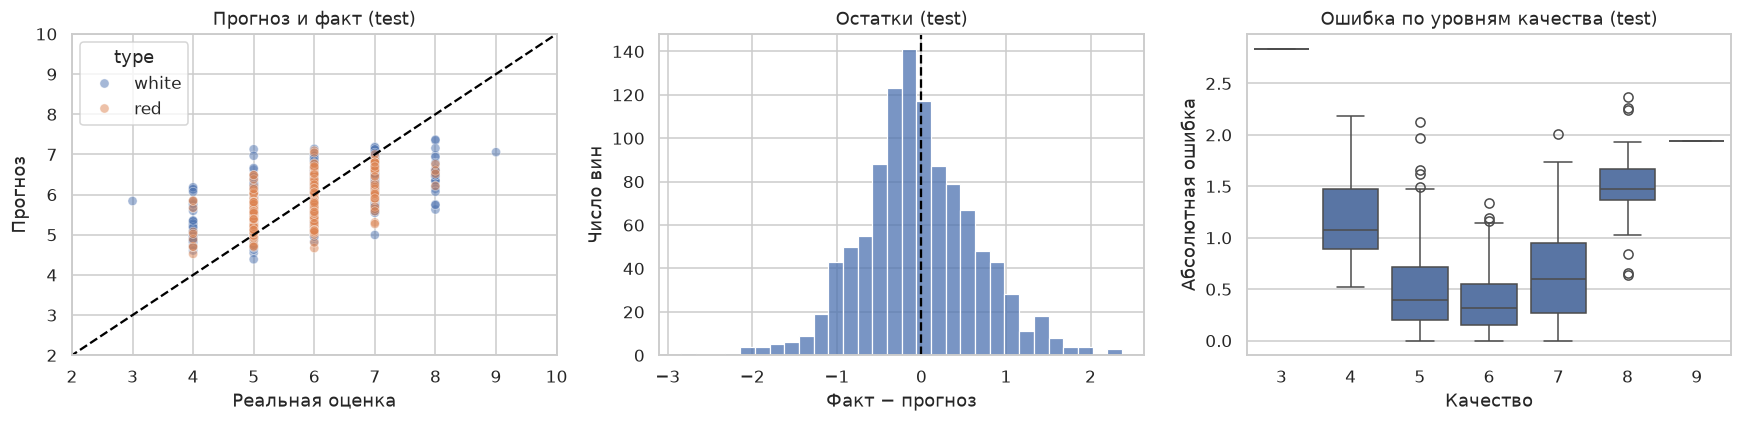

,n,MAE,mean_actual,mean_prediction
type,,,,
red,282,0.5021,5.6525,5.6546
white,784,0.5379,5.8406,5.8845


,n,MAE,mean_actual,mean_prediction
actual,,,,
3,1,2.8389,3.0,5.8389
4,47,1.2181,4.0,5.2181
5,365,0.4880,5.0,5.4669
6,448,0.3713,6.0,5.9149
7,172,0.6340,7.0,6.3743
8,32,1.4922,8.0,6.5078
9,1,1.9444,9.0,7.0556


,type,alcohol,volatile acidity,actual,predicted,abs_error
2544,white,10.1,0.20,3,5.8389,2.8389
217,white,9.6,0.26,8,5.6278,2.3722
3302,white,11.5,0.33,8,5.7389,2.2611
762,white,8.8,0.21,8,5.7556,2.2444
2012,white,10.2,0.21,4,6.1833,2.1833
1773,white,10.3,0.16,4,6.1333,2.1333
1210,white,10.1,0.28,4,6.1278,2.1278
2522,white,12.7,0.27,5,7.1278,2.1278


In [10]:
errors = X_test.copy()
errors['actual'] = y_test
errors['predicted'] = pred
errors['residual'] = y_test.to_numpy() - pred
errors['abs_error'] = np.abs(errors['residual'])
errors.to_csv(ARTIFACTS / 'test_predictions.csv', index_label='row_after_dedup')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=errors, x='actual', y='predicted', hue='type', alpha=0.5, ax=axes[0])
axes[0].plot([0, 10], [0, 10], '--', color='black', label='Идеальный прогноз')
axes[0].set(xlim=(2, 10), ylim=(2, 10), xlabel='Реальная оценка',
            ylabel='Прогноз', title='Прогноз и факт (test)')
sns.histplot(errors['residual'], bins=30, ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set(title='Остатки (test)', xlabel='Факт − прогноз', ylabel='Число вин')
sns.boxplot(data=errors, x='actual', y='abs_error', ax=axes[2])
axes[2].set(title='Ошибка по уровням качества (test)', xlabel='Качество', ylabel='Абсолютная ошибка')
plt.tight_layout()
plt.show()

def group_error_table(frame, column):
    return frame.groupby(column, observed=True).agg(
        n=('abs_error', 'size'), MAE=('abs_error', 'mean'),
        mean_actual=('actual', 'mean'), mean_prediction=('predicted', 'mean'),
    )

display(group_error_table(errors, 'type'))
display(group_error_table(errors, 'actual'))
display(errors.nlargest(8, 'abs_error')[['type', 'alcohol', 'volatile acidity',
                                        'actual', 'predicted', 'abs_error']])

### 5.2. Интерпретация, ошибки и ограничения

Оцениваем permutation importance на уже отложенной тестовой выборке:
поочерёдное перемешивание исходного признака и рост MAE. Эта процедура нужна
только для объяснения зафиксированной модели; повторного отбора признаков
или обучения по этим результатам нет. Коррелирующие показатели способны
замещать друг друга, поэтому важность не равна причинному влиянию.

,feature,MAE increase,std
11,alcohol,0.1749,0.0046
2,volatile acidity,0.0635,0.0045
6,free sulfur dioxide,0.0423,0.0047
10,sulphates,0.0239,0.0035
5,chlorides,0.0167,0.0023
9,pH,0.0166,0.0025
7,total sulfur dioxide,0.0146,0.0020
4,residual sugar,0.0140,0.0022
3,citric acid,0.0090,0.0018
8,density,0.0080,0.0012


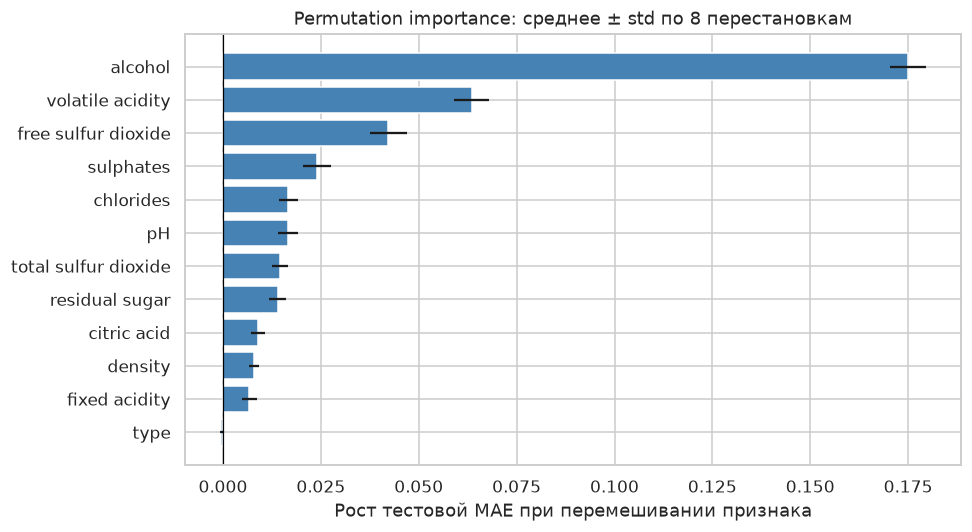

Наибольшее ухудшение MAE при перестановке дают: **alcohol, volatile acidity, free sulfur dioxide**.

In [11]:
importance_result = permutation_importance(
    best_model, X_test, y_test, scoring='neg_mean_absolute_error',
    n_repeats=8, random_state=SEED, n_jobs=N_JOBS,
)
importance = pd.DataFrame({
    'feature': X_test.columns,
    'MAE increase': importance_result.importances_mean,
    'std': importance_result.importances_std,
}).sort_values('MAE increase', ascending=False)
display(importance)
plot_importance = importance.sort_values('MAE increase')
plt.figure(figsize=(9, 5))
plt.barh(plot_importance['feature'], plot_importance['MAE increase'],
         xerr=plot_importance['std'], color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Рост тестовой MAE при перемешивании признака')
plt.title('Permutation importance: среднее ± std по 8 перестановкам')
plt.tight_layout()
plt.show()
importance.to_csv(ARTIFACTS / 'permutation_importance.csv', index=False)
top_features = ', '.join(importance.head(3)['feature'])
display(Markdown(f'Наибольшее ухудшение MAE при перестановке дают: **{top_features}**.'))

**Как читать результаты:**
- Таблица ошибок по `actual` показывает, насколько качество отличается для
  центральных и крайних оценок. У редких уровней мало наблюдений; нельзя делать
  вывод о надёжности только по их небольшой MAE или нескольким примерам.
- Раздельная MAE для красных и белых вин позволяет обнаружить различие качества
  прогноза, но сама по себе не доказывает его статистическую значимость.
- Остаток > 0 означает занижение оценки; < 0 — завышение. У регрессии на
  несбалансированной цели возможно стягивание редких оценок к средним.
- Случайное разбиение проверяет качество на данных из того же источника.
  Внешние вина, другие лаборатории и новые годы производства отдельно
  не проверены; причинные выводы и гарантия производственного качества невозможны.
- Подбор гиперпараметров делает CV-оценку лучшего варианта оптимистичной.
  Поэтому основной отчётный результат — нетронутый при подборе test.
- Критерий 10% — учебный ориентир. Промышленное применение требует внешнего
  пилота и допустимой ошибки, согласованной с технологом.

## 6. Deployment — применение и сопровождение

### 6.1. Прототип применения

Сохраняем весь `Pipeline` вместе с медианами, масштабированием, кодировщиком
и моделью. Сохраняется модель, обученная **только на train**: это именно тот
объект, для которого получены тестовые метрики. Пример ниже использует одну
реальную входную строку test без передачи целевой оценки в модель.

Для шкалы интерфейса прогноз можно ограничить диапазоном 0–10, но метрики
выше считаются по исходным прогнозам. Пример — демонстрация вызова,
а не дополнительная оценка качества.

In [12]:
model_path = ARTIFACTS / 'wine_quality_pipeline.joblib'
joblib.dump(best_model, model_path)
loaded_model = joblib.load(model_path)  # Загружать только доверенные joblib-файлы.
example = X_test.iloc[[0]].copy()
example_prediction = loaded_model.predict(example)[0]
display(example)
print(f'Прогноз: {example_prediction:.2f}; '
      f'отображение в диапазоне 0–10: {np.clip(example_prediction, 0, 10):.2f}')
assert np.allclose(loaded_model.predict(X_test), pred)

report = {
    'dataset': 'rajyellow46/wine-quality', 'dataset_version': 1,
    'sha256': data_sha256, 'seed': SEED,
    'raw_rows': len(raw), 'duplicates_removed': n_duplicates,
    'train_rows': len(X_train), 'test_rows': len(X_test),
    'selected_model': best_name,
    'selected_params': searches[best_name].best_params_,
    'cv_mae': float(cv_table.loc[best_name, 'CV MAE']),
    'test_metrics': test_metrics, 'baseline_test_metrics': baseline_metrics,
    'relative_mae_improvement': improvement,
    'success_threshold': 0.10, 'success': bool(success),
    'versions': versions, 'python': platform.python_version(),
}
(ARTIFACTS / 'results.json').write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8',
)
print('Модель и таблицы сохранены в:', ARTIFACTS)

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.4,9.9


Прогноз: 5.69; отображение в диапазоне 0–10: 5.69
Модель и таблицы сохранены в: artifacts


### 6.2. План внедрения

1. Принимать тип вина и 11 показателей по фиксированной схеме. Проверять типы,
   единицы измерения, неизвестные категории и отсутствие всех показателей сразу.
   Поддержка отдельных пропусков моделью не заменяет контроль качества измерений.
2. Показывать прогноз как вспомогательную оценку; решение оставлять технологу.
3. Логировать версию модели, дату, входные показатели, прогноз и последующую
   экспертную оценку, когда она появится.
4. Контролировать долю пропусков, распределения признаков и MAE на новых
   размеченных данных; отдельно следить за типами вина и редкими уровнями качества.
5. При изменении данных пересматривать модель и сравнивать с текущей версией
   на новом независимом временном тесте. Для честной проверки нужны даты и партии.

CRISP-DM — итеративный процесс: неудовлетворительная внешняя оценка возвращает
к уточнению задачи, сбору данных и подготовке признаков, а не к подгонке старого test.

### Итоговые выводы

In [13]:
display(Markdown(f'''
1. Решена задача регрессии по шести этапам CRISP-DM на датасете из задания:
   **{len(raw):,}** исходных записей, 12 входных признаков и цель `quality`.
2. Выявлены пропуски и **{n_duplicates:,}** полных дубликатов. После удаления
   повторов осталось **{len(data):,}** записей; одинаковые входные строки
   не пересекаются между train/test и CV-фолдами.
3. Сравнены Dummy, Ridge, Random Forest и HistGradientBoosting.
   По 5-fold CV выбрана **{best_name}**, CV MAE = **{report['cv_mae']:.3f}**.
4. На отложенном тесте MAE = **{test_metrics['MAE']:.3f}**, RMSE =
   **{test_metrics['RMSE']:.3f}**, R² = **{test_metrics['R2']:.3f}**.
   MAE относительно Dummy снижена на **{improvement:.1%}**;
   учебный критерий **{'достигнут' if success else 'не достигнут'}**.
5. Сохранён и проверен единый pipeline; приведены пример применения,
   анализ ошибок и план мониторинга. Результаты относятся к данному
   разбиению и источнику данных, а не доказывают готовность к промышленному внедрению.
'''))


1. Решена задача регрессии по шести этапам CRISP-DM на датасете из задания:
   **6,497** исходных записей, 12 входных признаков и цель `quality`.
2. Выявлены пропуски и **1,168** полных дубликатов. После удаления
   повторов осталось **5,329** записей; одинаковые входные строки
   не пересекаются между train/test и CV-фолдами.
3. Сравнены Dummy, Ridge, Random Forest и HistGradientBoosting.
   По 5-fold CV выбрана **Random Forest**, CV MAE = **0.530**.
4. На отложенном тесте MAE = **0.528**, RMSE =
   **0.685**, R² = **0.393**.
   MAE относительно Dummy снижена на **19.6%**;
   учебный критерий **достигнут**.
5. Сохранён и проверен единый pipeline; приведены пример применения,
   анализ ошибок и план мониторинга. Результаты относятся к данному
   разбиению и источнику данных, а не доказывают готовность к промышленному внедрению.


## Источники

1. Raj Parmar. Wine Quality. Kaggle, версия 1:
   https://www.kaggle.com/datasets/rajyellow46/wine-quality
2. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences
   by data mining from physicochemical properties. *Decision Support Systems*,
   47(4), 547–553, 2009. https://doi.org/10.1016/j.dss.2009.05.016
3. UCI Machine Learning Repository. Wine Quality:
   https://archive.ics.uci.edu/dataset/186/wine+quality
4. scikit-learn. Pipelines and composite estimators:
   https://scikit-learn.org/stable/modules/compose.html
5. scikit-learn. Cross-validation:
   https://scikit-learn.org/stable/modules/cross_validation.html